[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/f8_geometry_gives_back_the_information.ipynb)

# The geometry gives back the information

* **Author**: simone.azeglio@gmail.com

* **Goal**: How do the stretches of a code add up to bits? The notebook checks the identity I(R; X) = (1/2) E[Tr G] of Azeglio, Laquitaine, Ferrari, Chalk (NeurIPS 2026, arXiv 2605.06304) on three neurons, on Gaussian stimuli with a linear code in closed form, and in its nearest-neighbour form on samples.

* **Needs**: a CPU, no data. `pip install multigeom`.

* **Time**: about 10 s.

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom`. Elsewhere this does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom

CPU times: user 4 μs, sys: 1 μs, total: 5 μs
Wall time: 6.2 μs


### 1.2. Imports

Import the packages, set the figure style and pick the device. Every tensor is float64, so the device is a CUDA GPU when there is one and the CPU otherwise (Apple's `mps` has no float64).

time: 2 secs

In [2]:
%%time

import math

import matplotlib.pyplot as plt
import torch

from multigeom.lowdim import (
    blur_levels,
    compute_g,
    gaussian_blurred_fisher,
    gaussian_g,
    gaussian_information,
    mutual_information,
    nearest_neighbour_directions,
    nearest_neighbour_information,
    to_bits,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_default_dtype(torch.float64)
print("device:", device)

# figure style of the Foundations notebooks: 10 pt text, no top or right spines
plt.rcParams.update(
    {
        "font.size": 10,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "legend.frameon": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

device: cpu
CPU times: user 1.06 s, sys: 188 ms, total: 1.25 s
Wall time: 2.18 s


### 1.3. Parameters

Two settings. First the three neurons of these notebooks. The stimulus $x$ lies on $[-3, 3]$ with the uniform prior $p(x) = 1/6$, and the responses are $r = \mathrm{tuning}(x) + \sigma z$, with $z$ a standard Gaussian and $\sigma = 0.1$. The neurons are the bell-shaped neuron $f(x) = e^{-x^2/2}$, its monotonic twin ($f(x)$ for $x < 0$, $2 - f(x)$ for $x \ge 0$) and the low-gain neuron (half the twin). Their grid is coarser than the converged one (1201 stimuli, 100 blur levels per decade).

Then a stimulus with two components and a Gaussian prior, with variances 4 and 0.25 along its two axes. A linear code with Fisher eigenvalues 4 and 0.25 encodes it. `SEED` fixes the random generator of the nearest-neighbour samples.

time: <1 sec

In [3]:
%%time

SIGMA = 0.1  # standard deviation of the response noise
N_STIMULI = 301  # stimuli on [-3, 3]
BLUR_PER_DECADE = 25  # blur levels per decade, from 1e-6 to 1e4

PRIOR_VARIANCES = (4.0, 0.25)  # variances of the stimuli along x1 and x2
FISHER_EIGENVALUES = (4.0, 0.25)  # Fisher information along and across the code
SEED = 0
SAMPLE_SIZES = (100, 300, 1000, 3000, 10000)  # numbers N of stimuli
REPEATS = 20  # independent draws per N

x = torch.linspace(-3, 3, N_STIMULI, device=device)
prior = torch.full_like(x, 1 / 6)
blur = blur_levels(1e-6, 1e4, BLUR_PER_DECADE, device=device)
bell = torch.exp(-(x**2) / 2)
twin = torch.where(x < 0, bell, 2 - bell)
neurons = {"bell-shaped": bell, "monotonic twin": twin, "low-gain": 0.5 * twin}

TEAL, ROSE, INK, GREY = "#2A8C7E", "#B23A62", "#1a1a1a", "#8a8a8a"

CPU times: user 548 μs, sys: 337 μs, total: 885 μs
Wall time: 734 μs


## 2. The identity

The multi-scale Fisher information $G(x)$ of Azeglio, Laquitaine, Ferrari, Chalk (NeurIPS 2026) is fixed by requirements on how distances shrink when the stimulus is blurred, and none of them mentions information. Yet the average of half its trace over the prior is the mutual information:

$$I(R; X) = \frac{1}{2}\, \mathbb{E}_x\big[\mathrm{Tr}\, G(x)\big]\ \text{nats} = \frac{1}{2 \ln 2}\, \mathbb{E}_x\big[\mathrm{Tr}\, G(x)\big]\ \text{bits}.$$

The trace $\mathrm{Tr}$ of a matrix is the sum of its diagonal entries, and one nat is $1/\ln 2 = 1.44$ bits. In one dimension the trace of $G$ is $G$ itself. The cell computes $G$ for the three neurons with `compute_g`, averages $G/2$ over the prior and compares the result with the mutual information computed directly from the responses.

time: 3 secs

In [4]:
%%time

identity = {}
for name, tuning in neurons.items():
    g = compute_g(x, tuning, prior, SIGMA, blur).g
    from_geometry = to_bits(0.5 * torch.trapezoid(prior * g, x)).item()
    direct = to_bits(mutual_information(x, tuning, prior, SIGMA)).item()
    identity[name] = (from_geometry, direct)
    print(f"{name:15s}: (1/2) E[G] = {from_geometry:.3f} bits, I(R; X) = {direct:.3f}")

bell-shaped    : (1/2) E[G] = 1.607 bits, I(R; X) = 1.603


monotonic twin : (1/2) E[G] = 2.427 bits, I(R; X) = 2.423


low-gain       : (1/2) E[G] = 1.667 bits, I(R; X) = 1.663
CPU times: user 1.93 s, sys: 644 ms, total: 2.58 s
Wall time: 3.42 s


The two columns are 1.60, 2.42 and 1.66 bits. On this grid they differ by 0.004 to 0.005 bits, and on the converged grid by less than 0.001 bits.

## 3. Stretch, summed over directions

A small step $dx = \ell\, u$, with $\ell$ its ordinary length and $u$ a unit vector, has G length $\ell \sqrt{u^\top G(x)\, u}$. We call $\sqrt{u^\top G(x)\, u}$ the stretch along $u$. For $n$ perpendicular unit directions $e_1, \dots, e_n$ the squared stretches add up to the trace, $\sum_k e_k^\top G\, e_k = \mathrm{Tr}\, G$, whichever perpendicular directions we choose. The identity therefore says that the mutual information, in nats, is half the squared stretch summed over perpendicular directions and averaged over stimuli.

### 3.1. Gaussian stimuli and linear neurons

One code has every quantity in closed form. The stimulus has a Gaussian prior with mean 0 and covariance matrix $\Sigma$, and a population responds linearly, $r = A x + \text{noise}$, with Gaussian noise of variance $\sigma^2$ in each neuron. Its Fisher information $J = A^\top A/\sigma^2$ is the same at every stimulus, and so is $G$:

$$G = \ln(\Sigma^{-1} + J) - \ln(\Sigma^{-1}),$$

with $\ln$ the matrix logarithm. When $\Sigma$ and $J$ share their eigenvectors $e_i$, with prior variances $s_i^2$ and Fisher eigenvalues $j_i$, $G = \sum_i \ln(1 + s_i^2 j_i)\, e_i e_i^\top$, and $\tfrac{1}{2}\mathrm{Tr}\, G = \tfrac{1}{2}\ln\det(I + \Sigma J)$, the information of a Gaussian channel. `gaussian_g` and `gaussian_information` return the two sides.

We use two cases. In the case "along" the sensitive direction of the code lies along the long axis of the stimulus cloud. In the case "across" the same code is turned by 90° to lie along the short axis. The cell defines the prior covariance and `turned_fisher(angle)`, the Fisher matrix turned by an angle in degrees.

time: <1 sec

In [5]:
%%time

prior_cov = torch.diag(torch.tensor(PRIOR_VARIANCES, device=device))


def turned_fisher(angle_deg):
    """The Fisher matrix with eigenvalues FISHER_EIGENVALUES, turned by an angle."""
    a = math.radians(angle_deg)
    rotation = torch.tensor(
        [[math.cos(a), -math.sin(a)], [math.sin(a), math.cos(a)]], device=device
    )
    return (
        rotation
        @ torch.diag(torch.tensor(FISHER_EIGENVALUES, device=device))
        @ rotation.T
    )

CPU times: user 285 μs, sys: 478 μs, total: 763 μs
Wall time: 2.06 ms


The cell computes, for each case, the mutual information, half the trace of $G$, the eigenvalues of $G$ and the bits of each axis, half the diagonal entry of $G$ along that axis in bits.

time: <1 sec

In [6]:
%%time

cases = {"along": turned_fisher(0), "across": turned_fisher(90)}
gaussian = {}
for name, fisher in cases.items():
    g = gaussian_g(prior_cov, fisher)
    gaussian[name] = {
        "G": g,
        "G eigenvalues": torch.linalg.eigvalsh(g).flip(0).tolist(),
        "I bits": to_bits(gaussian_information(prior_cov, fisher)).item(),
        "half trace bits": to_bits(0.5 * torch.trace(g)).item(),
        "bits per axis": to_bits(0.5 * torch.diagonal(g)).tolist(),
    }
    print(
        f"{name:6s}: I = {gaussian[name]['I bits']:.3f} bits, (1/2) Tr G = "
        f"{gaussian[name]['half trace bits']:.3f} bits, G eigenvalues "
        + ", ".join(f"{v:.3f}" for v in gaussian[name]["G eigenvalues"])
        + " | bits per axis "
        + ", ".join(f"{v:.3f}" for v in gaussian[name]["bits per axis"])
    )

along : I = 2.087 bits, (1/2) Tr G = 2.087 bits, G eigenvalues 2.833, 0.061 | bits per axis 2.044, 0.044
across: I = 1.000 bits, (1/2) Tr G = 1.000 bits, G eigenvalues 0.693, 0.693 | bits per axis 0.500, 0.500
CPU times: user 1.18 ms, sys: 1.81 ms, total: 3 ms
Wall time: 10 ms


In the case "along" the products $s_i^2 j_i$ are 16 and 0.0625, the eigenvalues of $G$ are $\ln 17 = 2.83$ and $\ln 1.0625 = 0.061$, and the information is $2.044 + 0.044 = 2.087$ bits. In the case "across" both products are 1, both eigenvalues of $G$ are $\ln 2 = 0.69$, and the information is 1.00 bit. The Fisher information has the same eigenvalues in both cases, only turned. The code of the case "across" spends its high sensitivity on a direction in which the stimuli vary little.

### 3.2. The closed form against the integral over blur levels

$G$ is the integral over blur levels of the Fisher information of the blurred code, $J_t$, which `gaussian_blurred_fisher` gives in closed form. The cell integrates it with the trapezoid rule and compares the result with `gaussian_g`. It also gives $J_t$ at $t = 1$ in the case "across".

time: <1 sec

In [7]:
%%time

levels = blur_levels(1e-6, 1e6, 50, device=device)
for name, fisher in cases.items():
    integral = torch.trapezoid(
        gaussian_blurred_fisher(prior_cov, fisher, levels), levels, dim=0
    )
    gap = (integral - gaussian[name]["G"]).abs().max().item()
    print(f"{name:6s}: largest |integral of J_t - closed form G| = {gap:.4f}")

j_one = gaussian_blurred_fisher(prior_cov, cases["across"], torch.tensor([1.0]))[0]
print(
    f"across, t = 1: J_t is {j_one[0, 0]:.3f} along x1 and {j_one[1, 1]:.3f} along x2 "
    f"(at t = 0: {cases['across'][0, 0]:.2f} and {cases['across'][1, 1]:.2f})"
)

along : largest |integral of J_t - closed form G| = 0.0010
across: largest |integral of J_t - closed form G| = 0.0002
across, t = 1: J_t is 0.133 along x1 and 0.089 along x2 (at t = 0: 0.25 and 4.00)
CPU times: user 1.32 ms, sys: 505 μs, total: 1.83 ms
Wall time: 2.88 ms


The integral matches the closed form to about 0.001, the error of the trapezoid rule on 50 blur levels per decade. In the case "across", $J_t$ is 16 times larger along the short axis at $t = 0$, but at $t = 1$ it is already larger along the long axis, 0.13 against 0.089. As the blur grows, the blurred code changes mainly when the blurred stimulus moves along the directions in which the stimuli vary, and $J_t$ is weighted towards them.

### 3.3. Figure: the same Fisher information, turned

Top: the case "along". Bottom: the case "across". Each panel shows stimuli drawn from the prior (grey dots), the prior at one standard deviation (black), and the ellipses of $J$ (teal) and $G$ (rose), with half-axes proportional to the square roots of the eigenvalues, on one scale for $J$ and one for $G$ in both panels.

time: <1 sec

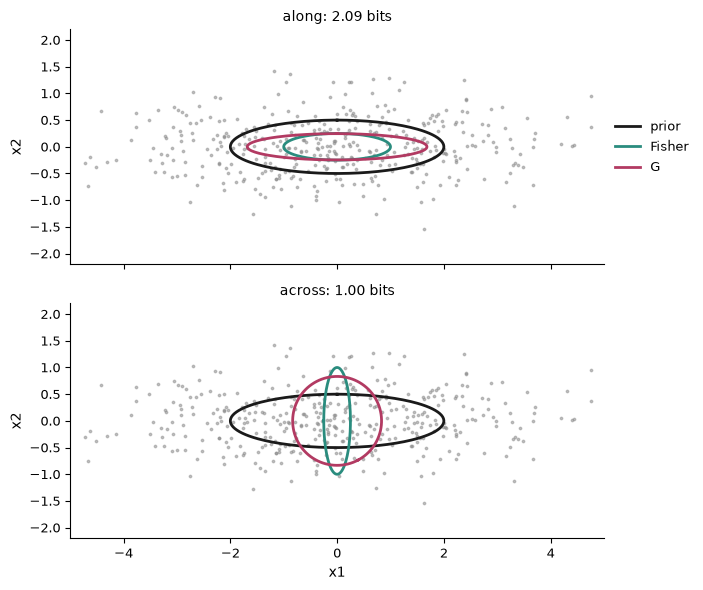

CPU times: user 116 ms, sys: 19.1 ms, total: 135 ms
Wall time: 151 ms


In [8]:
%%time


def ellipse(matrix, scale):
    """The ellipse with half-axes scale * sqrt(eigenvalues) along the eigenvectors."""
    values, vectors = torch.linalg.eigh(matrix.cpu())
    angle = torch.linspace(0, 2 * math.pi, 200)
    circle = torch.stack([angle.cos(), angle.sin()])
    return scale * vectors @ (values.clamp_min(0).sqrt()[:, None] * circle)


generator = torch.Generator().manual_seed(SEED)
cloud = torch.randn(400, 2, generator=generator) * torch.tensor(PRIOR_VARIANCES).sqrt()
fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
for ax, (name, fisher) in zip(axes, cases.items()):
    ax.scatter(cloud[:, 0], cloud[:, 1], s=3, color=GREY, alpha=0.5)
    for matrix, colour, scale, label in (
        (prior_cov, INK, 1.0, "prior"),
        (fisher, TEAL, 0.5, "Fisher"),
        (gaussian[name]["G"], ROSE, 1.0, "G"),
    ):
        ax.plot(*ellipse(matrix, scale), color=colour, lw=2, label=label)
    ax.set(aspect="equal", xlim=(-5, 5), ylim=(-2.2, 2.2), ylabel="x2")
    ax.set_title(f"{name}: {gaussian[name]['I bits']:.2f} bits", fontsize=10)
axes[1].set_xlabel("x1")
axes[0].legend(loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
plt.show()

In the case "along" the ellipse of $G$ is long and thin along $x_1$, with axes in the ratio $\sqrt{2.83/0.061} = 6.8$. In the case "across" it is a circle, although the Fisher ellipse has only turned.

## 4. Nearest neighbours

The identity also has a form that needs only stimuli as they occur. Draw $N$ stimuli $x^{(1)}, \dots, x^{(N)}$ from the prior. Each $x^{(i)}$ has a nearest neighbour at ordinary distance $d_i$ and G distance $d_{G,i}$, and $m_i = d_{G,i}/d_i$ is the magnification of the pair. For a stimulus with $n$ components,

$$I(R; X) = \frac{n}{2}\, \lim_{N \to \infty} \frac{1}{N} \sum_{i=1}^{N} m_i^2\ \text{nats}.$$

As $N$ grows, the neighbour comes closer, $m_i^2$ becomes the squared stretch $u_i^\top G\, u_i$ along the direction $u_i$ of the neighbour, and the directions become uniform, so their average squared stretch is $\mathrm{Tr}\, G/n$. `nearest_neighbour_information(samples, g)` computes $\frac{n}{2}$ times the mean of $u_i^\top G(x^{(i)})\, u_i$. In the Gaussian example $G$ is the same at every stimulus, so $m_i^2$ is exactly $u_i^\top G\, u_i$.

The cell draws `REPEATS` independent samples for each $N$ in the case "along" and keeps the mean and the standard deviation of the estimate, in bits.

time: 5 secs

In [9]:
%%time

prior_sd = torch.tensor(PRIOR_VARIANCES, device=device).sqrt()
g_along = gaussian["along"]["G"]
generator = torch.Generator(device=device).manual_seed(SEED)
estimates, long_axis_share = {}, {}
for n_samples in SAMPLE_SIZES:
    draws, shares = [], []
    for _ in range(REPEATS):
        samples = (
            torch.randn(n_samples, 2, generator=generator, device=device) * prior_sd
        )
        draws.append(to_bits(nearest_neighbour_information(samples, g_along)).item())
        if not shares:  # direction check on the first draw of each N
            shares.append(
                (nearest_neighbour_directions(samples)[:, 0] ** 2).mean().item()
            )
    estimates[n_samples] = torch.tensor(draws)
    long_axis_share[n_samples] = shares[0]
    print(
        f"N = {n_samples:5d}: {estimates[n_samples].mean():.3f} +- "
        f"{estimates[n_samples].std():.3f} bits | mean u1^2 = "
        f"{long_axis_share[n_samples]:.2f}"
    )
print(f"mutual information: {gaussian['along']['I bits']:.3f} bits")

N =   100: 2.081 +- 0.130 bits | mean u1^2 = 0.50


N =   300: 2.069 +- 0.086 bits | mean u1^2 = 0.49


N =  1000: 2.085 +- 0.068 bits | mean u1^2 = 0.49


N =  3000: 2.072 +- 0.025 bits | mean u1^2 = 0.51


N = 10000: 2.084 +- 0.019 bits | mean u1^2 = 0.51
mutual information: 2.087 bits
CPU times: user 7.32 s, sys: 2.32 s, total: 9.64 s
Wall time: 5.8 s


The estimate stays within its spread of 2.087 bits at every $N$, and the spread over the draws shrinks from about 0.13 bits at $N = 100$ to about 0.02 bits at $N = 10{,}000$, roughly as $1/\sqrt{N}$. In the first draw of each $N$, the squared component of the neighbour directions along the long axis is between 0.49 and 0.51: the directions are spread evenly, as the limit requires. Larger $N$, up to 300,000 stimuli, shrinks the spread further, at a cost that grows as $N^2$.

### 4.1. Figure: convergence of the nearest-neighbour form

Mean (dots) and one standard deviation (bars) of the estimate over the draws, against the number of stimuli, with the mutual information dashed.

time: <1 sec

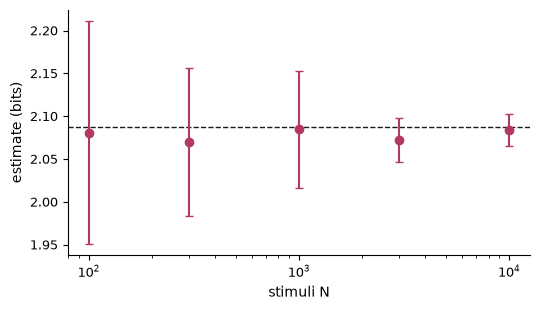

CPU times: user 133 ms, sys: 11.9 ms, total: 145 ms
Wall time: 150 ms


In [10]:
%%time

means = [estimates[n].mean().item() for n in SAMPLE_SIZES]
spreads = [estimates[n].std().item() for n in SAMPLE_SIZES]
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.axhline(gaussian["along"]["I bits"], ls="--", color=INK, lw=1)
ax.errorbar(SAMPLE_SIZES, means, yerr=spreads, fmt="o", color=ROSE, capsize=3)
ax.set_xscale("log")
ax.set_xlabel("stimuli N")
ax.set_ylabel("estimate (bits)")
fig.tight_layout()
plt.show()

## 5. Try it

1. Turn the code by 45° with `turned_fisher(45)`. The information falls to 1.73 bits, and the leading eigenvector of $G$ points at 15° from $x_1$ while that of $J$ points at 45°: $G$ stays closer to the long axis of the cloud.
2. Raise the larger Fisher eigenvalue from 4 to 16 and then to 100 in `FISHER_EIGENVALUES`. The larger eigenvalue of $G$, $\ln(1 + 4 j_1)$, grows only from 2.83 to 4.17 and 5.99, and the information from 2.09 to 3.05 and 4.37 bits.
3. In the case "across", shrink the short axis of the cloud from 0.5 to 0.1 (variance 0.01). The eigenvalue of $G$ across the cloud falls from 0.69 to 0.04, while $J$ does not change.

The cell carries out the first change.

time: <1 sec

In [11]:
%%time

fisher_45 = turned_fisher(45)
g_45 = gaussian_g(prior_cov, fisher_45)


def leading_angle(matrix):
    """Angle of the leading eigenvector from the x1 axis, in degrees, in [0, 90]."""
    vector = torch.linalg.eigh(matrix)[1][:, -1]
    return math.degrees(math.atan(abs(vector[1].item() / vector[0].item())))


info_45 = to_bits(gaussian_information(prior_cov, fisher_45)).item()
print(
    f"turned by 45 degrees: I = {info_45:.2f} bits, (1/2) Tr G = "
    f"{to_bits(0.5 * torch.trace(g_45)).item():.2f} bits"
)
print(
    "G eigenvalues:",
    [round(v, 2) for v in torch.linalg.eigvalsh(g_45).flip(0).tolist()],
)
print(
    f"leading eigenvector: G at {leading_angle(g_45):.0f} degrees, J at "
    f"{leading_angle(fisher_45):.0f} degrees"
)

turned by 45 degrees: I = 1.73 bits, (1/2) Tr G = 1.73 bits
G eigenvalues: [2.21, 0.19]
leading eigenvector: G at 15 degrees, J at 45 degrees
CPU times: user 970 μs, sys: 561 μs, total: 1.53 ms
Wall time: 1.45 ms


Half the trace of $G$ still equals the information, 1.73 bits. The eigenvalues of $G$ are 2.21 and 0.19, and its leading eigenvector lies at 15°, much closer to the long axis of the cloud than the 45° of $J$. The prior pulls the geometry towards the directions in which the stimuli vary.